In [1]:
!pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df =pd.read_csv('/Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/regression/car_fuel_efficiency_2026.csv')

In [4]:
df.head(10)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
5,2007,USA,Hybrid,Front-wheel drive,2,2290,6,266.0,4260,18.8,31.2
6,1992,Asia,Gasoline,Front-wheel drive,2,2270,6,250.0,4310,21.7,26.8
7,2005,USA,Gasoline,Front-wheel drive,4,2370,6,279.0,4090,17.4,30.2
8,1997,Asia,Gasoline,Rear-wheel drive,3,2330,6,251.0,4230,19.5,30.9
9,2004,USA,Diesel,All-wheel drive,5,2330,6,280.0,4620,17.7,31.2


In [5]:
df=df.fillna(0)

Skewness: 0.081


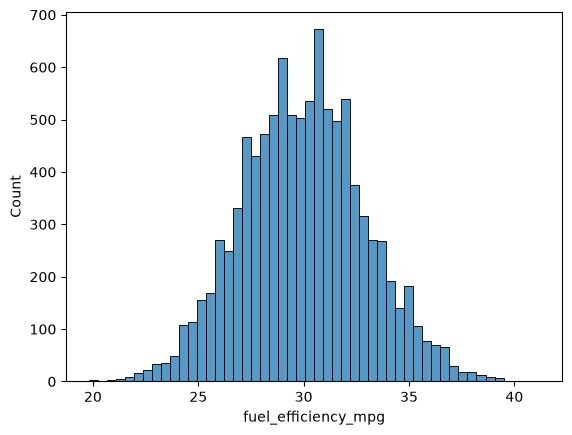

In [6]:
sns.histplot(df.fuel_efficiency_mpg, bins=50) #no long tail 
#check symmetry 
print(f"Skewness: {df['fuel_efficiency_mpg'].skew():.3f}")
 #looks relatively normally distributed

In [7]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,0.0,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,0.0,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [8]:
from sklearn.model_selection import train_test_split

In [9]:

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


In [10]:
from sklearn.feature_extraction import DictVectorizer

In [11]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

In [17]:
Y_train = df_train.fuel_efficiency_mpg.values
Y_val = df_val.fuel_efficiency_mpg.values
Y_test = df_test.fuel_efficiency_mpg.values

Question 1

Let's train a decision tree regressor to predict the `fuel_efficiency_mpg` variable. 

* Train a model with `max_depth=1`.


Which original feature is used for splitting the data? If you use
`DictVectorizer`, map a one-hot feature such as `origin=USA` back to its
original column name.


* `'vehicle_weight'`
* `'model_year'`
* `'origin'`
* `'fuel_type'`



In [12]:
from sklearn.tree import DecisionTreeClassifier

In [18]:
X_train

array([[1.90e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 1.00e+00, 4.28e+03],
       [1.88e+01, 1.00e+00, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.58e+03],
       [2.06e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.15e+03],
       ...,
       [1.91e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 0.00e+00, 4.44e+03],
       [1.94e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.00e+03],
       [1.78e+01, 0.00e+00, 1.00e+00, ..., 1.00e+00, 0.00e+00, 4.27e+03]],
      shape=(6000, 17))

In [19]:
Y_train

array([30.8, 29.7, 27.6, ..., 30.7, 32.1, 29.6], shape=(6000,))

In [16]:
dt = DecisionTreeClassifier(max_depth=1, random_state=11) #depth of tree will not be infinite
dt.fit(X_train, Y_train)

ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

Question 2

Train a random forest regressor with these parameters:

* `n_estimators=10`
* `random_state=1`
* `n_jobs=-1` (optional - to make training faster)


What's the RMSE of this model on the validation data?

* 0.1837
* 1.837
* 18.37
* 183.7




Question 3

Now let's experiment with the `n_estimators` parameter

* Try these values of this parameter: `[10, 50, 100, 150]`.
* Set `random_state` to `1`.
* Evaluate the model on the validation dataset.


Which value gives the lowest validation RMSE? Consider 3 decimal places for
calculating the answer.

- 10
- 50
- 100
- 150

Question 4

Let's select the best `max_depth`:

* Try different values of `max_depth`: `[10, 15, 20, 25]`
* For each of these values,
  * try different values of `n_estimators` from `[10, 50, 100, 150]`
  * calculate the mean RMSE 
* Fix the random seed: `random_state=1`


What's the best `max_depth`, using the mean RMSE?

* 10
* 15
* 20
* 25


# Que

Question 5

We can extract feature importance information from tree-based models. 

At each step of the decision tree learning algorithm, it finds the best split. 
When doing it, we can calculate "gain" - the reduction in impurity before and after the split. 
This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the
[`feature_importances_`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor.feature_importances_)
field. 

For this homework question, we'll find the most important feature:

* Train the model with these parameters:
  * `n_estimators=10`,
  * `max_depth=20`,
  * `random_state=1`,
  * `n_jobs=-1` (optional)
* Get the feature importance information from this model


What's the most important feature (among these 4)? 

* `vehicle_weight`
*	`horsepower`
* `acceleration`
* `engine_displacement

In [ ]:
Question 6

Now let's train an XGBoost model! For this question, we'll tune the `eta` parameter:

* Install XGBoost
* Create DMatrix for train and validation
* Create a watchlist
* Train a model with these parameters for 100 rounds:

```
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
```

Now change `eta` from `0.3` to `0.1`.

Which eta leads to the best RMSE score on the validation dataset?

* 0.3
* 0.1
* Both give equal value

## Learning in Public